# Customer Churn Analysis Using Python

## Project Objective

The objective of this project is to analyze customer churn patterns using Python and identify customer characteristics associated with higher churn rates. The analysis examines contract types, customer tenure, monthly charges, internet services, payment methods, and total charges to develop data-driven business recommendations for improving customer retention.

## Tools and Technologies
- Python
- Pandas
- Matplotlib
- Google Colab

## Dataset
IBM Telco Customer Churn dataset containing 7,043 customer records and 21 columns.

## Project Workflow
1. Data loading and initial exploration
2. Data quality checks and cleaning
3. Exploratory data analysis (EDA)
4. Visualization of customer churn patterns
5. Key findings and business recommendations

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.shape

(7043, 21)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [9]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [10]:
df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


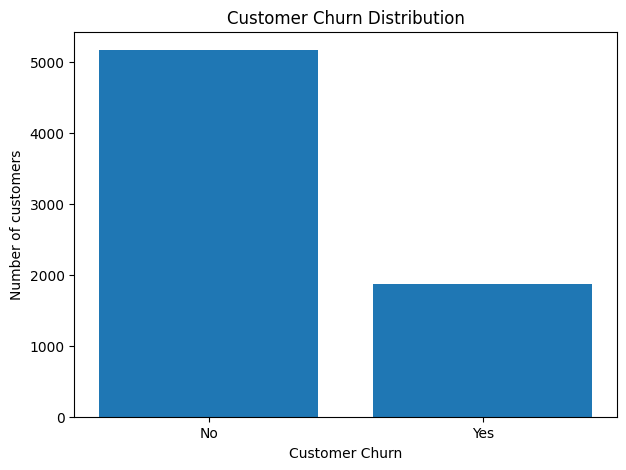

In [11]:
churn_counts = df['Churn'].value_counts()
plt.figure(figsize=(7,5))
plt.bar(churn_counts.index, churn_counts.values)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of customers')

plt.show()

In [12]:
pd.crosstab(df['Contract'],df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [13]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize = 'index'
)*100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


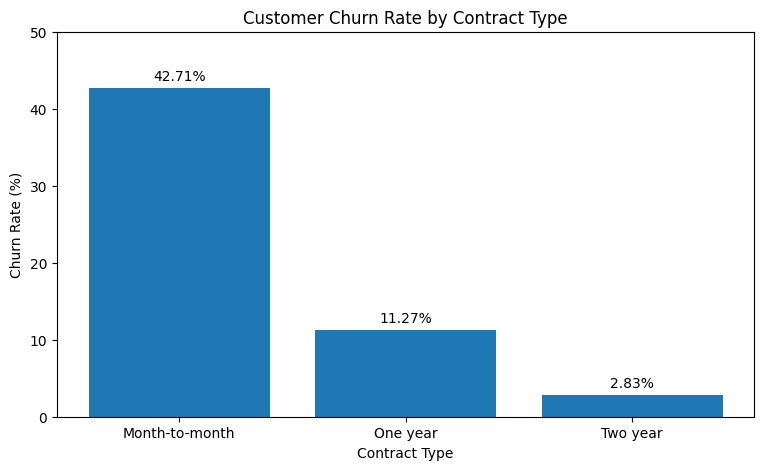

In [18]:
Churn_rates = contract_churn['Yes'].sort_values(ascending=False)


plt.figure(figsize=(9,5))

plt.bar(
    Churn_rates.index,
    Churn_rates.values
)

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.ylim(0,50)

for i, value in enumerate(Churn_rates.values):
  plt.text(i,value+1,f'{value:.2f}%',ha='center')

plt.show()

In [19]:
df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


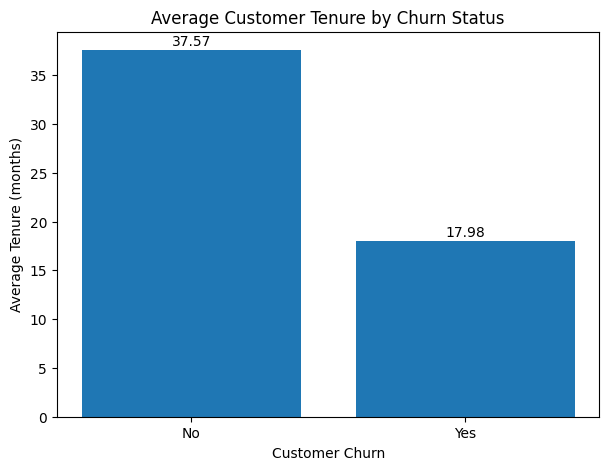

In [24]:
avg_tenure = df.groupby('Churn')['tenure'].mean()

plt.figure(figsize=(7,5))

plt.bar(avg_tenure.index, avg_tenure.values)

plt.title('Average Customer Tenure by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Average Tenure (months)')

for i, value in enumerate(avg_tenure.values):
  plt.text(i,value+0.5 , f'{value:.2f}' , ha='center')

plt.show()

In [25]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


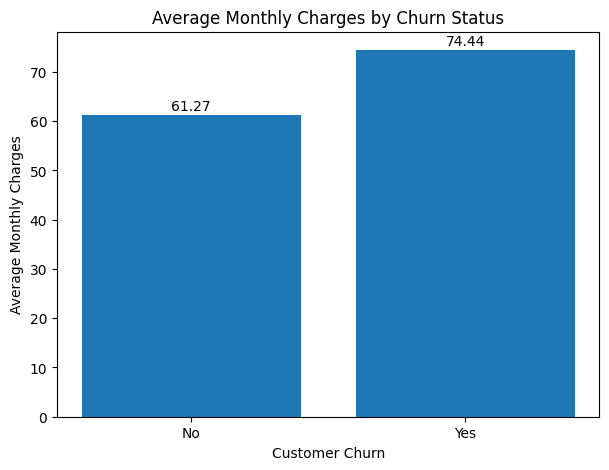

In [26]:
avg_charges = df.groupby('Churn')['MonthlyCharges'].mean()

plt.figure(figsize=(7,5))
plt.bar(avg_charges.index,avg_charges.values)

plt.title('Average Monthly Charges by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Average Monthly Charges')

for i, value in enumerate(avg_charges.values):
  plt.text(i, value + 1 , f'{value:.2f}' , ha='center')

plt.show()

In [27]:
pd.crosstab(df['InternetService'],df['Churn'])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [28]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize = 'index'
)*100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


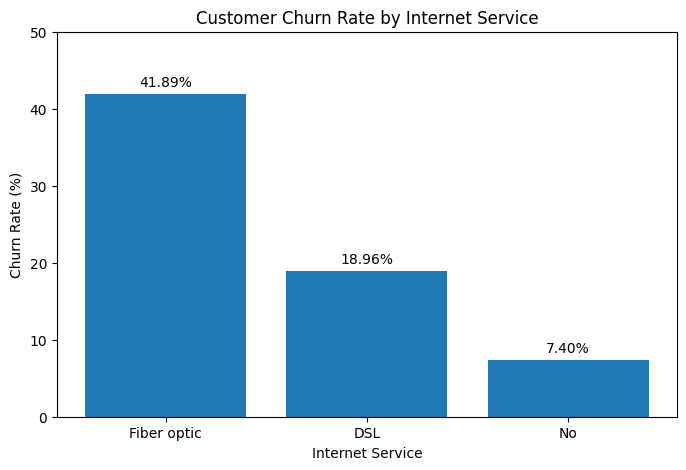

In [29]:
internet_churn_rate = internet_churn['Yes'].sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(internet_churn_rate.index, internet_churn_rate.values)

plt.title('Customer Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.ylim(0,50)

for i, value in enumerate(internet_churn_rate.values):
  plt.text(i,value+1,f'{value:.2f}%',ha='center')

plt.show()

In [30]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize = 'index'
)*100

payment_churn


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


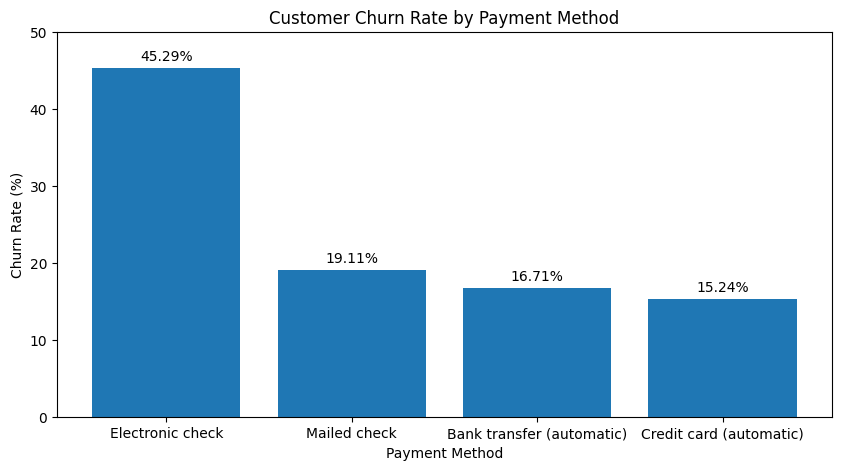

In [31]:
payment_churn_rate = payment_churn['Yes'].sort_values(ascending=False)

plt.figure(figsize=(10,5))
plt.bar(payment_churn_rate.index, payment_churn_rate.values)

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.ylim(0,50)

for i, value in enumerate(payment_churn_rate.values):
  plt.text(i,value+1,f'{value:.2f}%',ha='center')

plt.show()

In [32]:
df['TotalCharges'].dtype

dtype('O')

In [33]:
df['TotalCharges'].str.strip().eq('').sum()

np.int64(11)

In [34]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors = 'coerce'
)

df['TotalCharges'].isnull().sum()


np.int64(11)

In [35]:
df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges','Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [37]:
df.groupby('Churn')['TotalCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,2555.344141,2329.456984,18.80,577.825,1683.60,4264.125,8672.45
Yes,1869.0,1531.796094,1890.822994,18.85,134.500,703.55,2331.300,8684.80


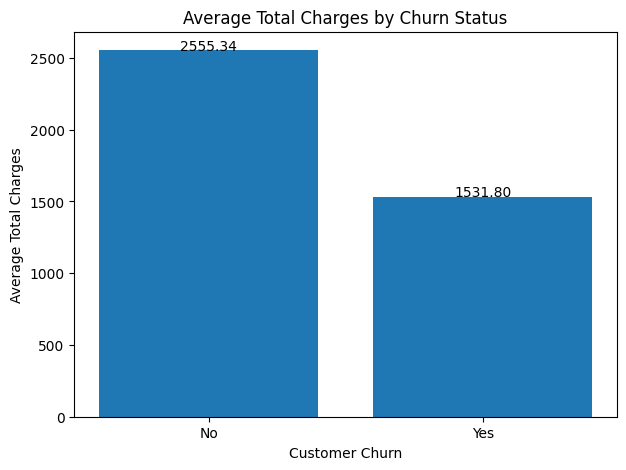

In [38]:
avg_total_charges = df.groupby('Churn')['TotalCharges'].mean()

plt.figure(figsize=(7,5))
plt.bar(avg_total_charges.index, avg_total_charges.values)

plt.title('Average Total Charges by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Average Total Charges')

for i, value in enumerate(avg_total_charges.values):
  plt.text(i, value + 1 , f'{value:.2f}' , ha='center')

plt.show()

1. Overall churn: Approximately 26.54% of customers left the service.
2. Contract type: Month-to-month customers had the highest churn rate at 42.71%, compared with 2.83% for two-year contract customers.
3. Customer tenure: Customers who churned had an average tenure of 17.98 months, compared with 37.57 months for customers who stayed.
4. Monthly charges: Churned customers paid an average of 74.44 per month, compared with 61.27 for customers who stayed.
5. Internet service: Fiber optic customers had the highest churn rate at 41.89%.
6. Payment method: Electronic-check customers had the highest churn rate at 45.29%.
7. Total charges: Churned customers had lower average total charges, consistent with their shorter average tenure.

## Business Recommendations

1. **Improve month-to-month customer retention:** Offer suitable loyalty benefits, discounts, or incentives to encourage customers to consider longer-term contracts.

2. **Investigate fiber optic customer churn:** Examine customer feedback, service quality, pricing, and technical issues to understand why fiber optic customers leave at a higher rate.

3. **Focus on early-stage customers:** Introduce onboarding support and follow-up communications during the first months of service, when customers may be more likely to leave.

4. **Review electronic-check payment patterns:** Investigate whether payment difficulties, billing experiences, or customer preferences are associated with the higher churn rate among electronic-check users.

5. **Review pricing and customer value:** Evaluate whether customers paying higher monthly charges receive sufficient value through service quality, support, and suitable packages.

6. **Monitor churn regularly:** Build a dashboard to track churn rates by contract type, tenure, internet service, payment method, and monthly charges.

These recommendations should be tested against customer feedback and further data before implementation. The observed relationships do not, by themselves, establish the causes of churn.

In [39]:
print("Dataset shape:", df.shape)
print("\nMissing values in TotalCharges:", df['TotalCharges'].isnull().sum())
print("\nDuplicate customer IDs:", df['customerID'].duplicated().sum())
print("\nChurn distribution:")
print(df['Churn'].value_counts(normalize=True).mul(100).round(2))

Dataset shape: (7043, 21)

Missing values in TotalCharges: 11

Duplicate customer IDs: 0

Churn distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
